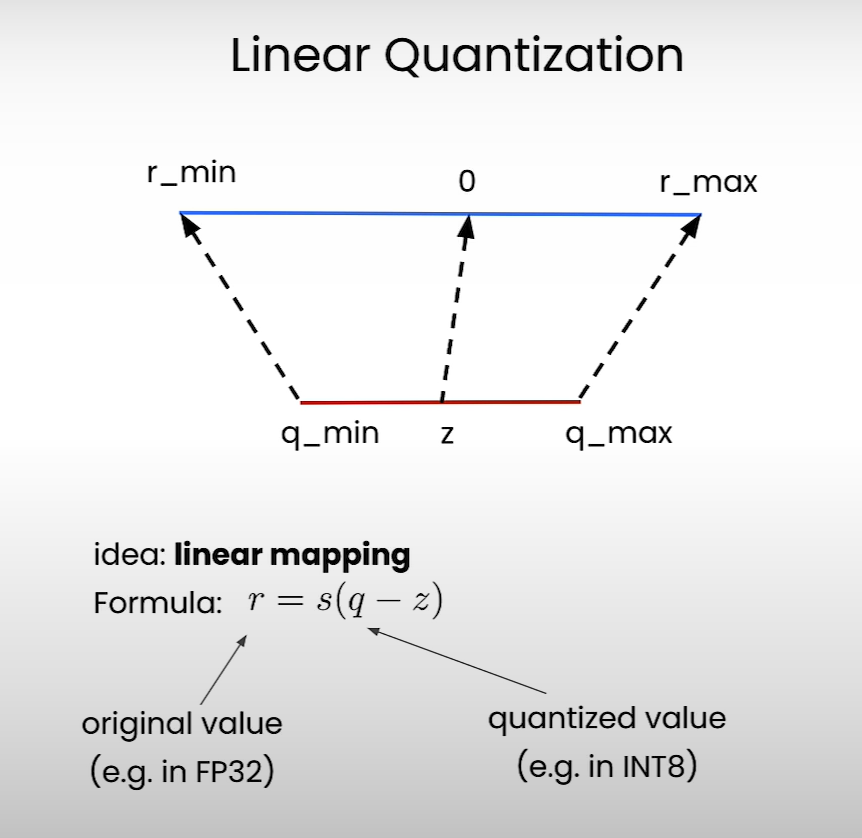

In [46]:
from IPython.display import Image, display

display(Image(filename="linear_quantization_formula.png", width=600, height=200))

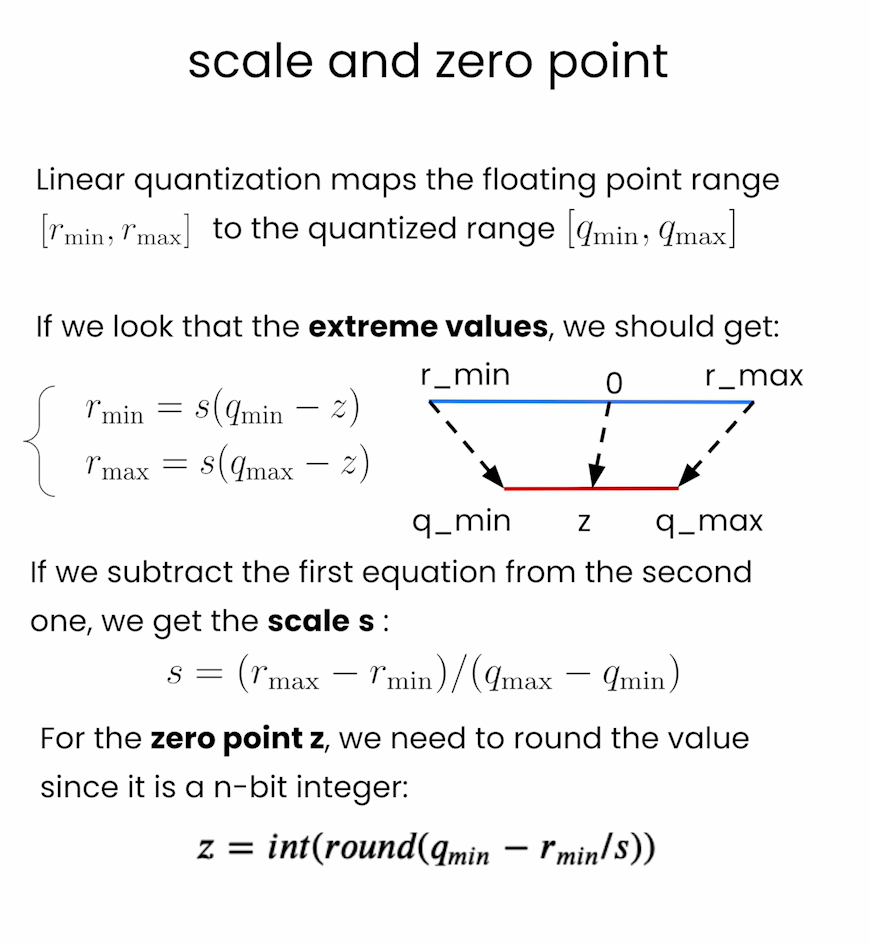

In [1]:
from IPython.display import Image, display

display(Image(filename="scale_zero_point_values.png", width=600, height=200))

In [2]:
import torch

In [3]:
test_tensor=torch.tensor(
    [[191.6, -13.5, 728.6],
     [92.14, 295.5,  -184],
     [0,     684.6, 245.5]]
)

In [4]:
r_min = test_tensor.min().item()
r_max = test_tensor.max().item()

In [5]:
r_min

-184.0

In [6]:
r_max

728.5999755859375

In [7]:
q_min=torch.iinfo(torch.int8).min
q_max=torch.iinfo(torch.int8).max

In [8]:
q_min

-128

In [9]:
q_max

127

In [10]:
scale = (r_max - r_min) / (q_max - q_min)

In [11]:
scale

3.578823433670343

In [12]:
zero_point = q_min - (r_min / scale)

In [13]:
zero_point

-76.58645490333825

In [14]:
zero_point = int(round(zero_point))

In [15]:
zero_point

-77

In [16]:
def get_q_scale_and_zero_point(tensor, dtype=torch.int8):
    
    q_min, q_max = torch.iinfo(dtype).min, torch.iinfo(dtype).max
    r_min, r_max = tensor.min().item(), tensor.max().item()

    scale = (r_max - r_min) / (q_max - q_min)

    zero_point = q_min - (r_min / scale)

    # clip the zero_point to fall in [quantized_min, quantized_max]
    if zero_point < q_min:
        zero_point = q_min
    elif zero_point > q_max:
        zero_point = q_max
    else:
        # round and cast to int
        zero_point = int(round(zero_point))
    
    return scale, zero_point

In [17]:
new_scale, new_zero_point = get_q_scale_and_zero_point(
    test_tensor)

In [18]:
new_scale

3.578823433670343

In [19]:
new_zero_point

-77

In [20]:
from helper import linear_q_with_scale_and_zero_point , linear_dequantization, plot_quantization_errors


In [21]:
quantized_tensor = linear_q_with_scale_and_zero_point(
    test_tensor, new_scale, new_zero_point)

In [22]:
dequantized_tensor = linear_dequantization(quantized_tensor,
                                           new_scale, new_zero_point)

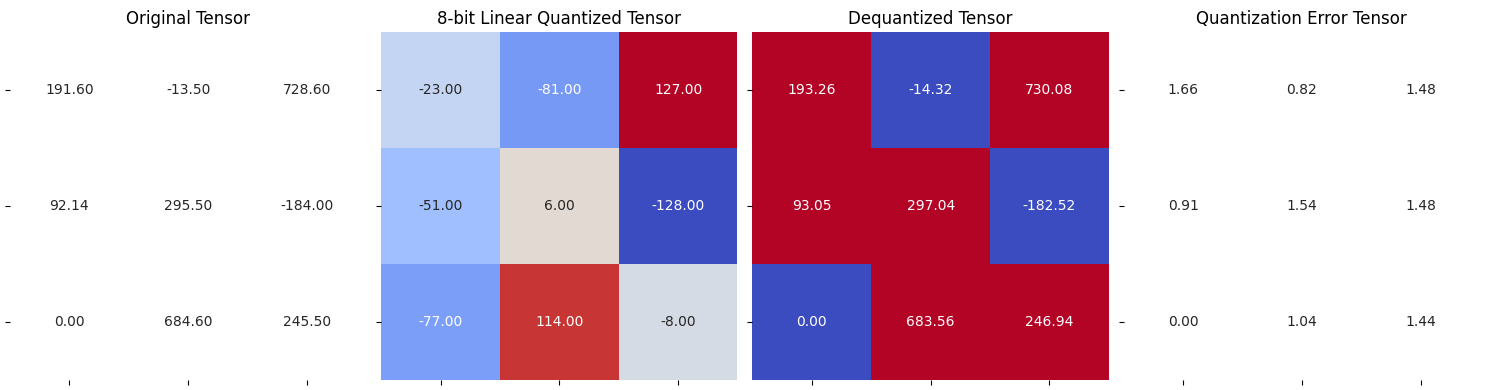

In [23]:
plot_quantization_errors(test_tensor, quantized_tensor, 
                         dequantized_tensor)

In [24]:
(dequantized_tensor-test_tensor).square().mean()

tensor(1.5730)

In [25]:
def linear_quantization(tensor, dtype=torch.int8):
    scale, zero_point = get_q_scale_and_zero_point(tensor, 
                                                   dtype=dtype)
    
    quantized_tensor = linear_q_with_scale_and_zero_point(tensor,
                                                          scale, 
                                                          zero_point, 
                                                          dtype=dtype)
    
    return quantized_tensor, scale , zero_point

In [26]:
r_tensor = torch.randn((4, 4))

In [27]:
r_tensor

tensor([[ 0.5794, -0.0371,  0.6195, -0.6788],
        [-1.3583,  0.5902,  1.3226,  0.5092],
        [ 0.2422, -1.2086,  0.0606, -2.2250],
        [ 0.3082,  2.3813,  0.6722,  0.7579]])

In [28]:
quantized_tensor, scale, zero_point = linear_quantization(r_tensor)

In [29]:
quantized_tensor

tensor([[  27,   -7,   29,  -43],
        [ -80,   28,   68,   23],
        [   8,  -72,   -2, -128],
        [  12,  127,   32,   37]], dtype=torch.int8)

In [30]:
scale

0.0180636864082486

In [31]:
zero_point

-5

In [32]:
dequantized_tensor = linear_dequantization(quantized_tensor,
                                           scale, zero_point)

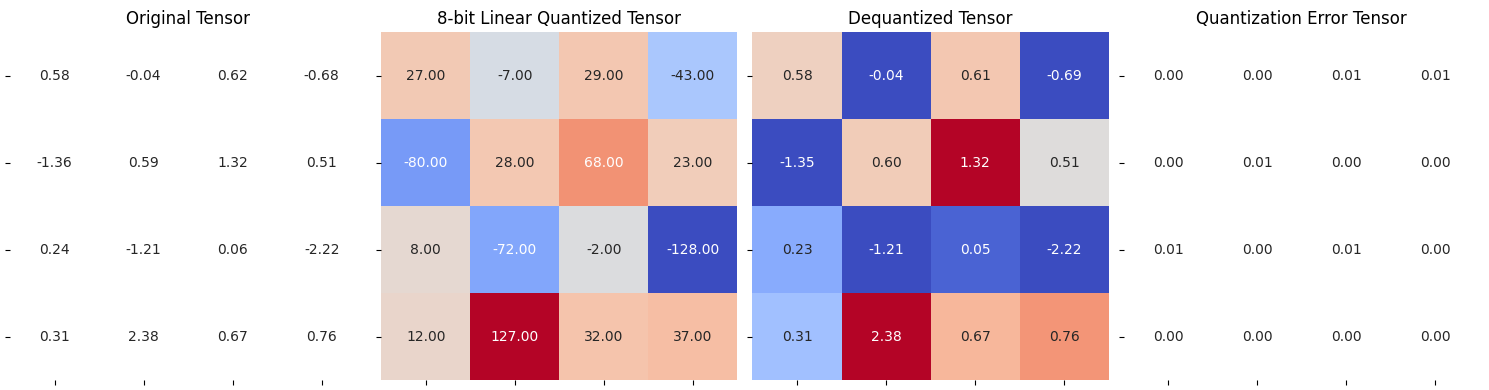

In [33]:
plot_quantization_errors(r_tensor, quantized_tensor,
                         dequantized_tensor)

In [34]:
(dequantized_tensor-r_tensor).square().mean()

tensor(1.8612e-05)